# Entrenamiento de modelos

In [ ]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

import warnings
warnings.filterwarnings('ignore')

# EDA (Análisis estadístico de datos) en Características

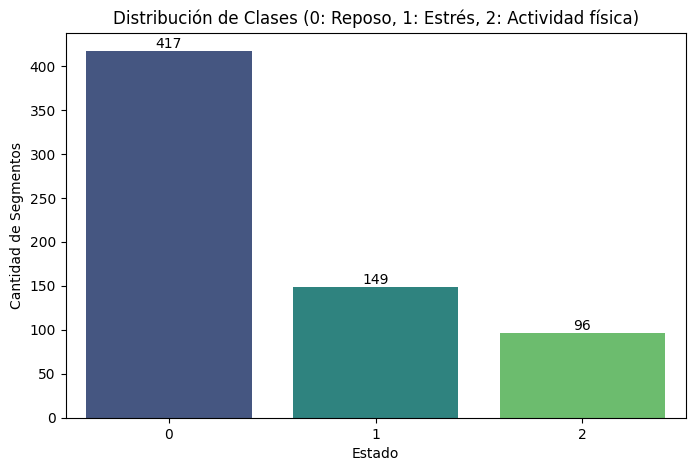

In [ ]:
# Cargar el dataset completo
df = pd.read_csv('SignalFeatures_Dataset.csv') 

# Conteo de Estados
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='Estado', data=df, palette='viridis')
plt.title('Distribución de Clases (0: Reposo, 1: Estrés, 2: Actividad física)')
plt.ylabel('Cantidad de Segmentos')

# Añadimos el conteo sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom')
plt.show()

In [4]:
# Forma del dataset
print("Shape:", df.shape)

Shape: (662, 179)


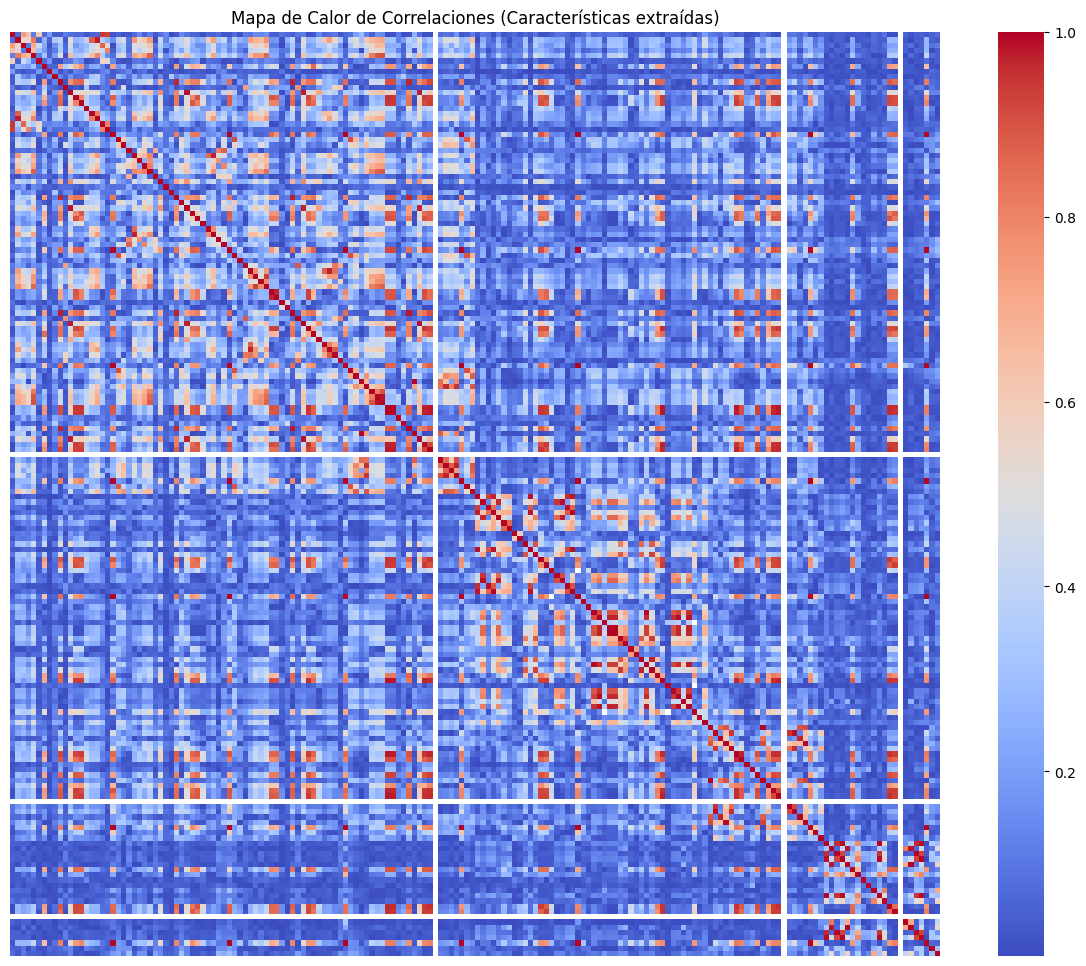

In [31]:
# Análisis de Correlación
# Separamos temporalmente las columnas que sabemos que NO son predictores numéricos
columnas_excluir = ['Estado']

X_temp = df.drop(columns=columnas_excluir)

# Seleccionar estrictamente columnas matemáticas (ignora el datetime)
X_temp_numerico = X_temp.select_dtypes(include=[np.number])

plt.figure(figsize=(15, 12))
corr_matrix = X_temp_numerico.corr().abs() 
sns.heatmap(corr_matrix, cmap='coolwarm', xticklabels=False, yticklabels=False)
plt.title('Mapa de Calor de Correlaciones (Características extraídas)')
plt.show()

# Comprobación de calidad de datos

In [ ]:
# Creamos un DataFrame para almacenar nuestro reporte
auditoria = pd.DataFrame(index=X_temp_numerico.columns)

# Conteo de NaNs (Vacíos)
auditoria['NaNs'] = X_temp_numerico.isna().sum()

# Conteo de Infinitos (Positivos y Negativos)
# isinf() devuelve True para inf y -inf
auditoria['Infinitos'] = np.isinf(X_temp_numerico).sum()

# Total de defectos y porcentaje
auditoria['Total_Defectos'] = auditoria['NaNs'] + auditoria['Infinitos']
total_filas = len(X_temp_numerico)
auditoria['%_Defectuoso'] = round((auditoria['Total_Defectos'] / total_filas) * 100, 2)

# Comprobación de Varianza Cero (Desviación estándar igual a 0)
# Reemplazamos temporalmente inf con NaN solo para poder calcular la desviación estándar matemáticamente
std_dev = X_temp_numerico.replace([np.inf, -np.inf], np.nan).std()
auditoria['Varianza_Cero'] = std_dev == 0

# Filtramos para mostrar SOLO las columnas que requieren nuestra atención
columnas_problematicas = auditoria[(auditoria['Total_Defectos'] > 0) | (auditoria['Varianza_Cero'] == True)]

# Ordenamos por las que tienen mayor porcentaje de defectos
columnas_problematicas = columnas_problematicas.sort_values(by='%_Defectuoso', ascending=False)

if columnas_problematicas.empty:
    print("Los datos numéricos están limpios de NaNs, Infinitos y Varianzas Cero.")
else:
    print(f"Se encontraron problemas en {len(columnas_problematicas)} columnas:\n")
    
print(f"Total de filas en el dataset: {total_filas}")

columnas_problematicas

Se encontraron problemas en 8 columnas:

Total de filas en el dataset: 662


,NaNs,Infinitos,Total_Defectos,%_Defectuoso,Varianza_Cero
acc_y_entropy,0,472,472,71.30,False
acc_x_entropy,0,429,429,64.80,False
acc_z_entropy,0,346,346,52.27,False
phasic_entropy,0,313,313,47.28,False
tonic_entropy,0,127,127,19.18,False
l2_n_sign_changes,0,0,0,0.00,True
hr_n_sign_changes,0,0,0,0.00,True
temp_n_sign_changes,0,0,0,0.00,True


# Limpieza de columnas defectuosas o con poco poder predictivo

In [ ]:
# Identificar columnas con Varianza Cero
cols_varianza_cero = auditoria[auditoria['Varianza_Cero'] == True].index.tolist()

# Identificar columnas con excesivos defectos (Umbral > 15%)
cols_defectuosas = auditoria[auditoria['%_Defectuoso'] > 15].index.tolist()

# Unir ambas listas sin duplicados
columnas_basura = list(set(cols_varianza_cero + cols_defectuosas))

print(f"Columnas a eliminar ({len(columnas_basura)}):")
for col in columnas_basura:
    print(f" - {col}")

# Eliminar las columnas de nuestro dataset numérico
X_temp_numerico.drop(columns=columnas_basura, inplace=True)

print(f"\nLimpieza completada. Nuevas dimensiones de X_temp_numerico: {X_temp_numerico.shape}")

# Verificación de seguridad final
nans_restantes = X_temp_numerico.isna().sum().sum()
infs_restantes = np.isinf(X_temp_numerico).sum().sum()

print(f"Infinitos restantes en todo el dataset: {infs_restantes}")

Columnas a eliminar (8):
 - temp_n_sign_changes
 - tonic_entropy
 - hr_n_sign_changes
 - l2_n_sign_changes
 - acc_x_entropy
 - acc_y_entropy
 - acc_z_entropy
 - phasic_entropy

Limpieza completada. Nuevas dimensiones de X_temp_numerico: (662, 168)
Infinitos restantes en todo el dataset: 0


# Top 10 pares de características más correlacionadas

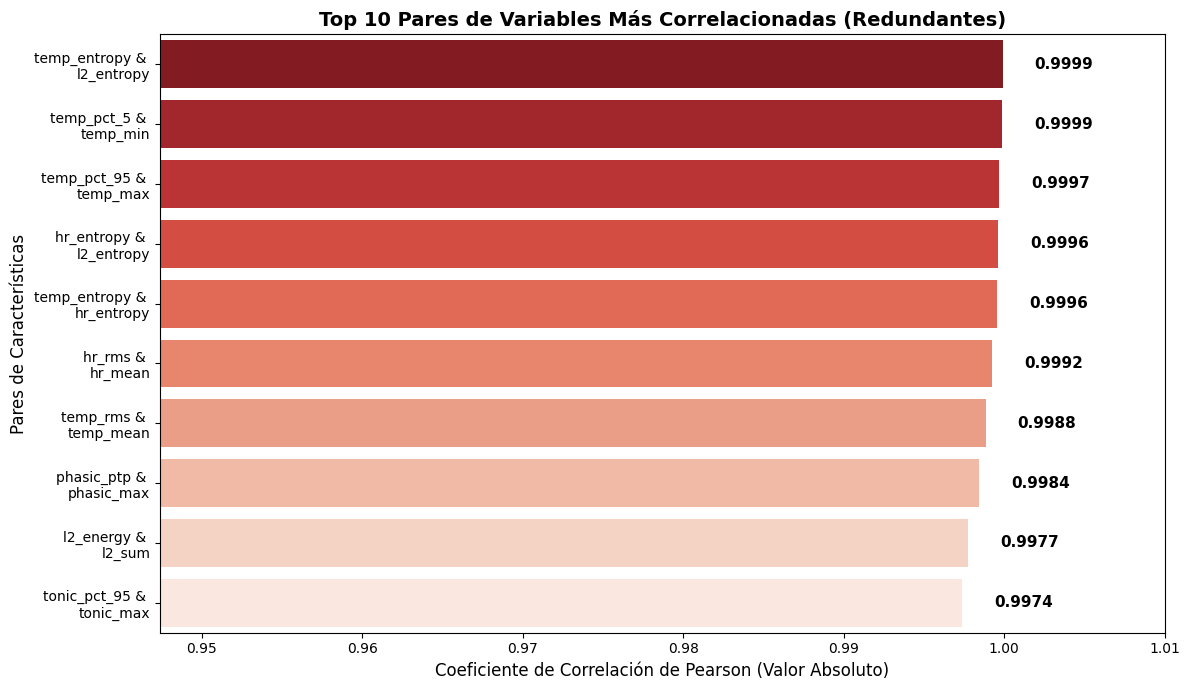

In [36]:
# Volvemos a calcular corr_matrix después de eliminar las 8 columnas defectuosas
corr_matrix = X_temp_numerico.corr().abs() 

# Tomamos el triángulo superior de la matriz de correlación (para no repetir pares ni la diagonal de 1.0)
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Apilamos la matriz a un formato de lista, eliminamos los vacíos y ordenamos de mayor a menor
correlaciones_ordenadas = upper_triangle.unstack().dropna().sort_values(ascending=False)

# Extraemos el Top 10
top_10_corr = correlaciones_ordenadas.head(10)

# Convertimos a DataFrame para graficar fácilmente
df_top_10 = top_10_corr.reset_index()
df_top_10.columns = ['Variable_1', 'Variable_2', 'Correlacion']
df_top_10['Pares'] = df_top_10['Variable_1'] + ' & \n' + df_top_10['Variable_2']

# Graficar en un diagrama de barras horizontales
plt.figure(figsize=(12, 7))
ax = sns.barplot(x='Correlacion', y='Pares', data=df_top_10, palette='Reds_r')

plt.title('Top 10 Pares de Variables Más Correlacionadas (Redundantes)', fontsize=14, fontweight='bold')
plt.xlabel('Coeficiente de Correlación de Pearson (Valor Absoluto)', fontsize=12)
plt.ylabel('Pares de Características', fontsize=12)

# Ajustamos el límite del eje X dinámicamente para que la gráfica tenga buen contraste
min_val = df_top_10['Correlacion'].min()
plt.xlim(min_val - 0.05, 1.01)

# Agregar el valor numérico exacto al final de cada barra
for p in ax.patches:
    width = p.get_width()
    plt.text(width + 0.002, 
             p.get_y() + p.get_height() / 2, 
             f'{width:.4f}', 
             ha='left', 
             va='center', 
             fontsize=11, 
             fontweight='bold')

plt.tight_layout()
plt.show()

# Eliminar variables con correlaciones altas > 0.85 
Para evitar redundancia de información en el conjunto de datos

In [37]:
print(f"Dimensiones de características predictivas originales: {X_temp_numerico.shape}")

# Umbral de correlación
umbral_correlacion = 0.85

# Seleccionar el triángulo superior de la matriz de correlación
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Encontrar las columnas con correlación mayor al umbral
columnas_a_eliminar = [column for column in upper.columns if any(upper[column] > umbral_correlacion)]

# Creamos una copia profunda y aislada de las características numéricas
X = X_temp_numerico.copy()

# Eliminamos las redundancias únicamente de la copia
X = X.drop(columns=columnas_a_eliminar)

# Copiamos nuestra variable objetivo por seguridad
y = df['Estado'].copy()

print(f"Características redundantes eliminadas: {len(columnas_a_eliminar)}")
print(f"Dimensiones de X (Copia) listas para entrenar: {X.shape}")

Dimensiones de características predictivas originales: (662, 168)
Características redundantes eliminadas: 91
Dimensiones de X (Copia) listas para entrenar: (662, 77)


# Preprocesamiento de datos
* Separación de datos (test/train) con GroupShuffleSplit para asegurarnos que las filas del mismo paciente (mismo PxID) se vayan juntas al mismo set
* Normalización con StandarScaler (Media 0, Desviación Estándar 1)

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# Extraemos la columna PxID directamente del dataframe original para usarla como grupos
grupos = df['PxID']

# GroupShuffleSplit asegura que las filas con el mismo PxID vayan juntas al mismo set
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Obtenemos los índices para separar los datos
train_idx, test_idx = next(gss.split(X, y, groups=grupos))

# Separamos X e y usando esos índices
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Mostramos cuántos pacientes únicos quedaron en cada set
pacientes_train = df.iloc[train_idx]['PxID'].nunique()
pacientes_test = df.iloc[test_idx]['PxID'].nunique()

print(f"Pacientes en Entrenamiento: {pacientes_train} | Pacientes en Prueba: {pacientes_test}")
print(f"Dimensiones X_train: {X_train.shape} | X_test: {X_test.shape}")

# Estandarización
scaler = StandardScaler()

# Ajustamos SOLO con los datos de entrenamiento
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Datos listos y escalados correctamente.")

--- PREPARANDO PARTICIÓN POR PACIENTES (Evitando Data Leakage) ---
Pacientes en Entrenamiento: 49 | Pacientes en Prueba: 13
Dimensiones X_train: (535, 77) | X_test: (127, 77)
Datos listos y escalados correctamente.


# Entrenamiento
Usamos un GridSearch para buscar el mejor modelo con sus mejores hiperparámetros, los modelos que vamos a probar son:
* Regresión logística multiclase
* Random Forest
* SVM (Support Vector Machine)
* XGBoost
* Red Neuronal MLP
* KNN

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

# Definición de Modelos a explorar con GridSearch
modelos = {
    'Regresion_Logistica': {
        'modelo': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42), 
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'solver': ['lbfgs', 'saga']
        }
    },
    'Random_Forest': {
        'modelo': RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 300, 500],
            'max_depth': [10, 20, 30, None],
            'min_samples_split': [2, 5, 10],
            'criterion': ['gini', 'entropy']
        }
    },
    'SVM': {
        'modelo': SVC(class_weight='balanced', probability=True, random_state=42),
        'params': {
            'C': [0.1, 1, 10, 50],
            'kernel': ['rbf', 'linear', 'poly'],
            'gamma': ['scale', 'auto']
        }
    },
    'XGBoost': {
        # XGBoost usa la GPU. No tiene class_weight directo en multinomial, pero f1_macro lo guiará
        'modelo': XGBClassifier(eval_metric='mlogloss', tree_method='hist', device='cuda', random_state=42),
        'params': {
            'n_estimators': [100, 300, 500],
            'learning_rate': [0.01, 0.05, 0.1, 0.2],
            'max_depth': [3, 6, 9],
            'subsample': [0.8, 1.0] # Ayuda a prevenir sobreajuste
        }
    },
    'Red_Neuronal_MLP': {
        'modelo': MLPClassifier(max_iter=2000, random_state=42),
        'params': {
            'hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001, 0.001, 0.01]
        }
    },
    'KNN': {
        'modelo': KNeighborsClassifier(n_jobs=-1),
        'params': {
            'n_neighbors': [3, 5, 7, 11],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan']
        }
    }
}

resultados = []
mejores_modelos = {}

print("Iniciando entrenamiento pesado y búsqueda de hiperparámetros...\n")

for nombre_modelo, config in modelos.items():
    inicio = time.time()
    print(f"Entrenando {nombre_modelo}...")
    
    clf = GridSearchCV(config['modelo'], config['params'], cv=5, scoring='f1_macro', n_jobs=-1 if nombre_modelo != 'XGBoost' else 1)
    clf.fit(X_train_scaled, y_train)
    
    tiempo_total = time.time() - inicio
    mejores_modelos[nombre_modelo] = clf.best_estimator_
    
    y_pred = clf.predict(X_test_scaled)
    
    # Calculamos ambas métricas para ver la comparativa
    acc = accuracy_score(y_test, y_pred)
    f1_mac = f1_score(y_test, y_pred, average='macro')
    
    resultados.append({
        'Modelo': nombre_modelo,
        'Mejor_F1_Macro_CV': clf.best_score_,
        'F1_Macro_Test': f1_mac,
        'Accuracy_Test': acc,
        'Tiempo_Segundos': round(tiempo_total, 2),
        'Mejores_Params': clf.best_params_
    })
    
    print(f"  ✓ Listo en {round(tiempo_total, 2)}s | F1-Macro Test: {f1_mac:.4f} | Acc Test: {acc:.4f}\n")

df_resultados = pd.DataFrame(resultados).sort_values(by='F1_Macro_Test', ascending=False)
display(df_resultados[['Modelo', 'F1_Macro_Test', 'Accuracy_Test', 'Mejor_F1_Macro_CV', 'Tiempo_Segundos']])

Iniciando entrenamiento pesado y búsqueda de hiperparámetros...

Entrenando Regresion_Logistica...
  ✓ Listo en 5.98s | F1-Macro Test: 0.7638 | Acc Test: 0.7874

Entrenando Random_Forest...
  ✓ Listo en 34.3s | F1-Macro Test: 0.8583 | Acc Test: 0.8661

Entrenando SVM...
  ✓ Listo en 6.12s | F1-Macro Test: 0.8022 | Acc Test: 0.8031

Entrenando XGBoost...
  ✓ Listo en 537.92s | F1-Macro Test: 0.8339 | Acc Test: 0.8583

Entrenando Red_Neuronal_MLP...
  ✓ Listo en 19.64s | F1-Macro Test: 0.7060 | Acc Test: 0.7795

Entrenando KNN...
  ✓ Listo en 0.36s | F1-Macro Test: 0.7084 | Acc Test: 0.7402



,Modelo,F1_Macro_Test,Accuracy_Test,Mejor_F1_Macro_CV,Tiempo_Segundos
1,Random_Forest,0.858267,0.866142,0.766103,34.30
3,XGBoost,0.833851,0.858268,0.756835,537.92
2,SVM,0.802243,0.803150,0.733372,6.12
0,Regresion_Logistica,0.763825,0.787402,0.734926,5.98
5,KNN,0.708399,0.740157,0.644863,0.36
4,Red_Neuronal_MLP,0.705951,0.779528,0.686843,19.64


### **Random Forest** fue el que tuvo mejor rendimiento con un Accuracy de **0.866**

# Evaluación del mejor modelo

--- Evaluando a detalle el mejor modelo: Random_Forest ---
               precision    recall  f1-score   support

   Reposo (0)       0.90      0.90      0.90        78
   Estrés (1)       0.71      0.69      0.70        29
Actividad (2)       0.95      1.00      0.98        20

     accuracy                           0.87       127
    macro avg       0.85      0.86      0.86       127
 weighted avg       0.86      0.87      0.87       127



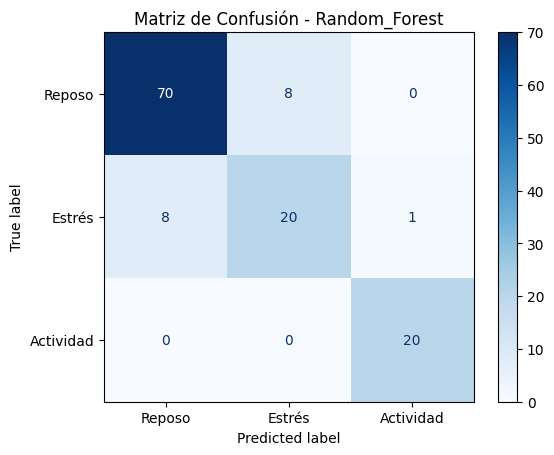

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Tomamos el modelo que haya quedado en primer lugar
nombre_mejor_modelo = df_resultados.iloc[0]['Modelo']
mejor_modelo_final = mejores_modelos[nombre_mejor_modelo]

print(f"--- Evaluando a detalle el mejor modelo: {nombre_mejor_modelo} ---")

y_pred_final = mejor_modelo_final.predict(X_test_scaled)

# Reporte de métricas por clase
print(classification_report(y_test, y_pred_final, target_names=['Reposo (0)', 'Estrés (1)', 'Actividad (2)']))

# Matriz de Confusión Visual
cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Reposo', 'Estrés', 'Actividad'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Matriz de Confusión - {nombre_mejor_modelo}')
plt.show()

### La ventaja de que Random Forest haya sido el modelo que nos dio mejores resultados es que podemos sacar una lista de las variables que tuvieron mayor importancia en las predicciones

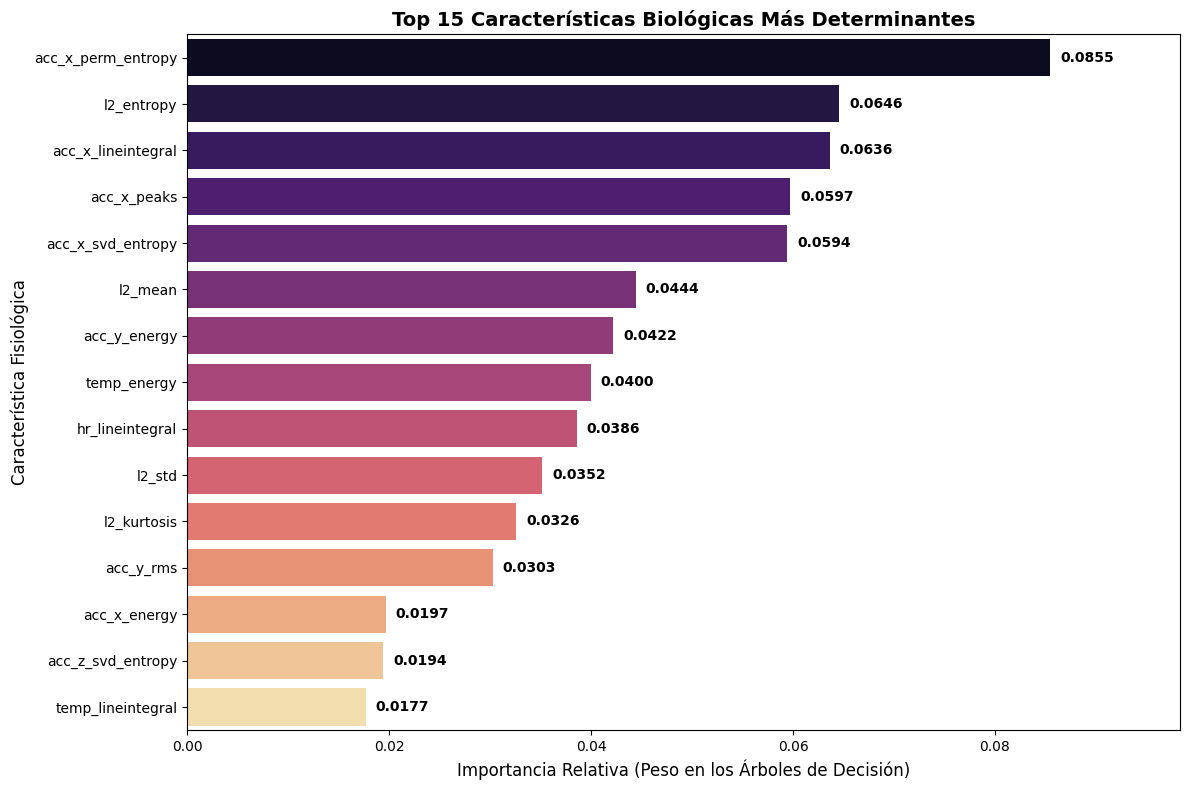

In [ ]:
# Extraemos el modelo Random Forest directamente del diccionario
mejor_rf = mejores_modelos['Random_Forest']

# Extraemos el arreglo matemático de importancias
importancias = mejor_rf.feature_importances_

# Emparejamos los valores con los nombres de las columnas originales
# (Usamos X_train porque conserva los nombres, a diferencia del array X_train_scaled)
nombres_caracteristicas = X_train.columns

df_importancias = pd.DataFrame({
    'Caracteristica': nombres_caracteristicas,
    'Importancia': importancias
})

# Ordenamos de mayor a menor y seleccionamos el Top 15
df_importancias = df_importancias.sort_values(by='Importancia', ascending=False).head(15)

# Visualización
plt.figure(figsize=(12, 8))
ax = sns.barplot(x='Importancia', y='Caracteristica', data=df_importancias, palette='magma')

plt.title('Top 15 Características Biológicas Más Determinantes', fontsize=14, fontweight='bold')
plt.xlabel('Importancia Relativa (Peso en los Árboles de Decisión)', fontsize=12)
plt.ylabel('Característica Fisiológica', fontsize=12)

# Ajustar límite del eje X para dar espacio a los números
plt.xlim(0, df_importancias['Importancia'].max() * 1.15)

# Añadir las etiquetas de valor exacto en cada barra
for p in ax.patches:
    width = p.get_width()
    plt.text(width + 0.001, 
             p.get_y() + p.get_height() / 2, 
             f'{width:.4f}', 
             ha='left', 
             va='center', 
             fontsize=10, 
             fontweight='bold')

plt.tight_layout()
plt.show()

# Curva ROC-AUC

--- EVALUACIÓN ROC-AUC (ONE-VS-REST) ---


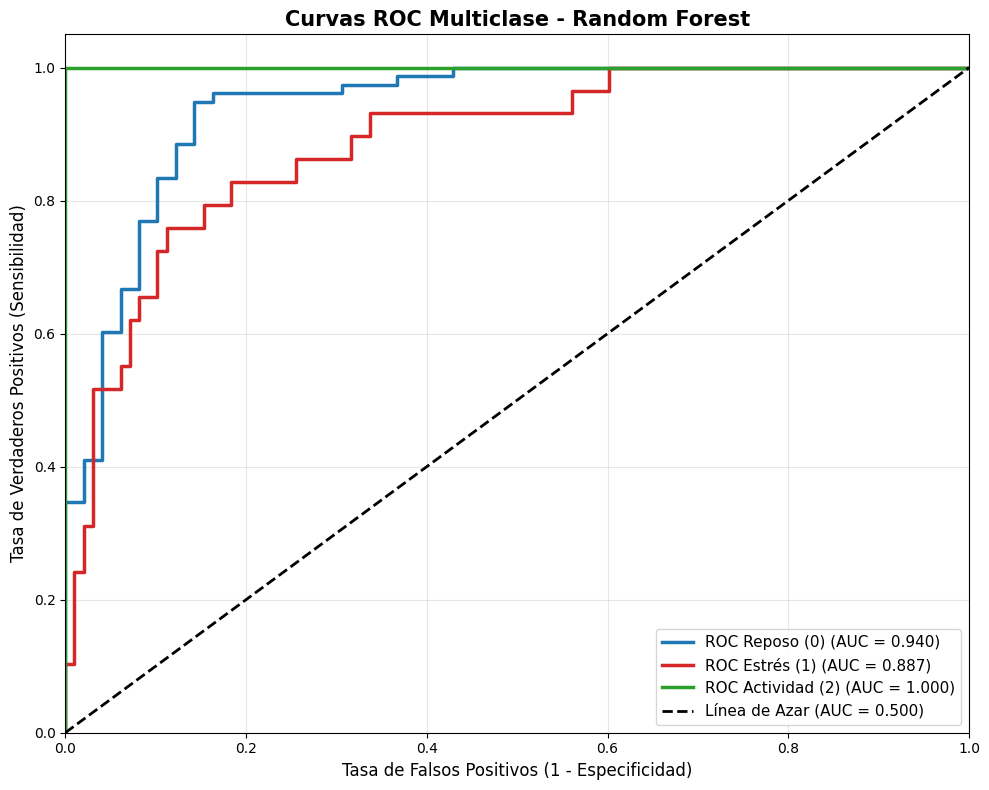

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

print("EVALUACIÓN ROC-AUC (ONE-VS-REST)")

# 1. Binarizar las etiquetas de prueba para la estrategia One-vs-Rest
# Esto convierte, por ejemplo, la clase 1 en [0, 1, 0]
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 2. Obtener las probabilidades de predicción del modelo ganador (Random Forest)
# No usamos .predict(), usamos .predict_proba() para obtener la certeza del modelo
y_score = mejor_rf.predict_proba(X_test_scaled)

# 3. Calcular la curva ROC y el AUC para cada clase individualmente
fpr = dict() # Tasa de Falsos Positivos
tpr = dict() # Tasa de Verdaderos Positivos
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Graficar
plt.figure(figsize=(10, 8))
colors = cycle(['#1f77b4', '#d62728', '#2ca02c']) # Colores profesionales (Azul, Rojo, Verde)
clases_nombres = ['Reposo (0)', 'Estrés (1)', 'Actividad (2)']

# Dibujar cada una de las 3 curvas
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC {clases_nombres[i]} (AUC = {roc_auc[i]:.3f})')

# Dibujar la línea de azar absoluto (peor escenario)
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Línea de Azar (AUC = 0.500)')

# Formateo de la gráfica
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=12)
plt.title('Curvas ROC Multiclase - Random Forest', fontsize=15, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()